# Pronosticar varios pasos hacia adelante (PyTorch)

En el notebook anterior pronosticamos **un solo día**: cuántas personas tomarán el metro de Chicago mañana. Pero en la práctica casi siempre se necesita más: para programar trenes y turnos de personal, la empresa de transporte quiere saber qué pasará en **las próximas dos semanas**.

En la presentación vimos dos formas de pronosticar varios pasos con una red recurrente:

1. **Uno a uno (autorregresivo):** entrenamos una red que predice un solo día, y la usamos 14 veces seguidas: cada pronóstico se agrega al final de la ventana como si fuera un dato real, y se vuelve a predecir.
2. **Todos a la vez (directo):** entrenamos una red cuya capa de salida tiene **14 neuronas**, una por cada día del horizonte.

En este notebook implementamos las dos con una **GRU** y las comparamos. La carga de datos, la red y la clase para entrenar son las del notebook anterior, así que van sin explicación aparte.

## Etapa 1: Se carga la base de datos.

In [1]:
import copy
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from tqdm import tqdm

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
data_dir = Path("data")
csv_path = data_dir / "ridership" / "CTA_-_Ridership_-_Daily_Boarding_Totals.csv"
if not csv_path.exists():
    data_dir.mkdir(exist_ok=True)
    tgz_path, _ = urllib.request.urlretrieve("https://github.com/ageron/data/raw/main/ridership.tgz",
                                             data_dir / "ridership.tgz")
    with tarfile.open(tgz_path) as f:
        f.extractall(data_dir)

df = pd.read_csv(csv_path, parse_dates=["service_date"], date_format="%m/%d/%Y")
df.columns = ["date", "day_type", "bus", "rail", "total"]
df = df.sort_values("date").set_index("date")
df = df.drop("total", axis=1)      # total = bus + rail, no aporta nada nuevo
df = df.drop_duplicates()          # el archivo trae algunos días repetidos
df.head()

,day_type,bus,rail
date,,,
2001-01-01,U,297192,126455
2001-01-02,W,780827,501952
2001-01-03,W,824923,536432
2001-01-04,W,870021,550011
2001-01-05,W,890426,557917


In [3]:
rail = df["rail"]
rail_train = torch.tensor(rail["2016-01":"2018-12"].values / 1e6, dtype=torch.float32)
rail_valid = torch.tensor(rail["2019-01":"2019-05"].values / 1e6, dtype=torch.float32)

## Etapa 2: Ventanas con un horizonte

Lo único nuevo en los datos es el **horizonte** (`horizon`): cuántos días hacia adelante queremos pronosticar. La entrada sigue siendo la ventana de los últimos 56 días; la etiqueta ahora son los **`horizon` días siguientes**.

```
entrada: d1 ... d56   →   etiqueta: d57 d58 ... d70   (horizon = 14)
```

Con `horizon=1` recuperamos exactamente el caso del notebook anterior.

In [4]:
class WindowDataset(Dataset):
    def __init__(self, series, window_length, horizon=1):
        self.series = series
        self.window_length = window_length
        self.horizon = horizon

    def __len__(self):
        return len(self.series) - self.window_length - self.horizon + 1

    def __getitem__(self, idx):
        end = idx + self.window_length
        window = self.series[idx:end].unsqueeze(-1)   # (pasos, 1 variable)
        target = self.series[end:end + self.horizon]  # (horizon,)
        return window, target


window_length, horizon = 56, 14
valid_series = torch.cat([rail_train[-window_length:], rail_valid])

def make_loaders(horizon):
    train_loader = DataLoader(WindowDataset(rail_train, window_length, horizon), batch_size=32, shuffle=True)
    valid_loader = DataLoader(WindowDataset(valid_series, window_length, horizon), batch_size=32)
    return train_loader, valid_loader

x, y = next(iter(make_loaders(horizon)[0]))
print("Entrada:", tuple(x.shape), " Etiqueta:", tuple(y.shape))

Entrada: (32, 56, 1)  Etiqueta: (32, 14)


### ¿Cómo se ve un ejemplo? Quién es X y quién es y

Cada ejemplo sigue siendo una pareja **(X, y)**, pero ahora **y también es un vector**:

- **X** (la entrada) es la ventana de 56 días seguidos: $X = (x_1, x_2, \dots, x_{56})$, donde $x_t$ son los pasajeros del día $t$ de la ventana.
- **y** (la etiqueta) son los **14 días siguientes**: $y = (y_1, y_2, \dots, y_{14})$, donde $y_1$ es el día 57, $y_2$ el día 58, y así.

En la tabla **cada fila es un ejemplo**: las columnas `x_1` a `x_56` forman X y las columnas `y_1` a `y_14` forman y (pandas oculta las del medio con `...`).

In [5]:
def windows_table(dataset, n=5, scale=1e6):
    # Una fila por ejemplo: columnas x_1 ... x_T (la entrada X) y la columna y (la etiqueta)
    rows = []
    for i in range(n):
        X, y = dataset[i]
        row = {f"x_{t + 1}": X[t, 0].item() * scale for t in range(len(X))}
        row.update({"y" if len(y) == 1 else f"y_{h + 1}": y[h].item() * scale for h in range(len(y))})
        rows.append(row)
    return pd.DataFrame(rows, index=[f"ejemplo {i + 1}" for i in range(n)]).round().astype(int)


with pd.option_context("display.max_columns", 12):
    display(windows_table(WindowDataset(rail_train, window_length, horizon)))

,x_1,x_2,x_3,x_4,x_5,x_6,...,y_9,y_10,y_11,y_12,y_13,y_14
ejemplo 1,319835,365509,287661,703185,727716,733167,...,421193,327173,739174,781301,768961,780687
ejemplo 2,365509,287661,703185,727716,733167,736809,...,327173,739174,781301,768961,780687,797977
ejemplo 3,287661,703185,727716,733167,736809,732495,...,739174,781301,768961,780687,797977,605182
ejemplo 4,703185,727716,733167,736809,732495,391597,...,781301,768961,780687,797977,605182,303129
ejemplo 5,727716,733167,736809,732495,391597,263073,...,768961,780687,797977,605182,303129,766595


La misma idea en una gráfica: el primer ejemplo, con los 56 valores de X en naranja y los 14 valores de y en verde.

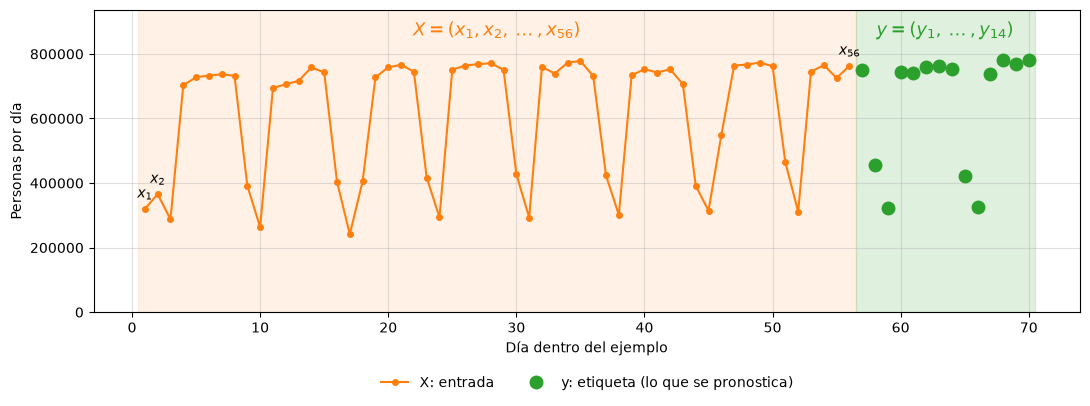

Forma de X: (56, 1)  Forma de y: (14,)


In [6]:
def plot_window(dataset, idx=0, scale=1e6):
    X, y = dataset[idx]
    x_vals, y_vals = X[:, 0].numpy() * scale, y.numpy() * scale
    T, H = len(x_vals), len(y_vals)
    t_x, t_y = np.arange(1, T + 1), np.arange(T + 1, T + H + 1)
    top = max(x_vals.max(), y_vals.max()) * 1.2

    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.axvspan(0.5, T + 0.5, color="tab:orange", alpha=0.1)       # zona de X
    ax.axvspan(T + 0.5, T + H + 0.5, color="tab:green", alpha=0.15)  # zona de y
    ax.plot(t_x, x_vals, "o-", color="tab:orange", ms=4, label="X: entrada")
    ax.plot(t_y, y_vals, "o", color="tab:green", ms=9, label="y: etiqueta (lo que se pronostica)")

    # Nombres de las zonas y de algunos valores
    ax.text((T + 1) / 2, top * 0.96, f"$X = (x_1, x_2, \\dots, x_{{{T}}})$", ha="center", va="top", fontsize=13, color="tab:orange")
    y_name = "$y$" if H == 1 else f"$y = (y_1, \\dots, y_{{{H}}})$"
    ax.text(T + (H + 1) / 2, top * 0.96, y_name, ha="center" if H > 1 else "left", va="top", fontsize=13, color="tab:green")
    for t in (1, 2, T):
        ax.annotate(f"$x_{{{t}}}$", (t, x_vals[t - 1]), textcoords="offset points", xytext=(0, 8), ha="center")

    ax.set_ylim(0, top)
    ax.set_xlabel("Día dentro del ejemplo"); ax.set_ylabel("Personas por día"); ax.grid(alpha=0.4)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()
    print("Forma de X:", tuple(X.shape), " Forma de y:", tuple(y.shape))


plot_window(WindowDataset(rail_train, window_length, horizon))

## Etapa 3: La red y la clase para entrenar (las del notebook anterior)

La red es la GRU del notebook anterior; lo único nuevo es `n_outputs`, cuántos números entrega la capa lineal final (1 día o 14 días). La clase `RidershipForecaster` es la misma: arma la red en `__init__` y tiene `train_epoch`, `evaluate`, `fit` y `predict`.

In [7]:
class GRUNet(nn.Module):
    def __init__(self, hidden_size=32, n_outputs=1):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, n_outputs)

    def forward(self, X):
        outputs, h_n = self.gru(X)        # (batch, pasos, hidden_size)
        return self.head(outputs[:, -1])  # (batch, n_outputs)

In [8]:
class RidershipForecaster:
    def __init__(self, n_outputs=1, hidden_size=32, lr=3e-3):
        # La red se arma dentro de la clase: una GRU con n_outputs salidas
        self.net = GRUNet(hidden_size=hidden_size, n_outputs=n_outputs).to(device)
        self.loss_fn = nn.HuberLoss()
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=lr)
        self.scale = 1e6  # para reportar el MAE en personas por día
        self.history = {"loss": [], "mae": [], "val_loss": [], "val_mae": []}

    def train_epoch(self, loader):
        # Una época: recorre todos los minibatches y actualiza los pesos
        self.net.train()
        total_loss, total_abs, n = 0.0, 0.0, 0
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            y_pred = self.net(X)
            loss = self.loss_fn(y_pred, y)
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item() * len(X)
            total_abs += (y_pred - y).abs().sum().item()
            n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * self.scale

    def evaluate(self, loader):
        # Mide el desempeño sin entrenar (sin calcular gradientes)
        self.net.eval()
        total_loss, total_abs, n = 0.0, 0.0, 0
        with torch.no_grad():
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                y_pred = self.net(X)
                total_loss += self.loss_fn(y_pred, y).item() * len(X)
                total_abs += (y_pred - y).abs().sum().item()
                n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * self.scale

    def fit(self, train_loader, valid_loader, epochs=100):
        best_mae, best_state = float("inf"), None
        pbar = tqdm(range(epochs), desc="Entrenamiento", unit="época")
        for epoch in pbar:
            loss, mae = self.train_epoch(train_loader)
            val_loss, val_mae = self.evaluate(valid_loader)
            for key, value in zip(self.history, (loss, mae, val_loss, val_mae)):
                self.history[key].append(value)
            if val_mae < best_mae:  # guardamos los mejores pesos
                best_mae, best_state = val_mae, copy.deepcopy(self.net.state_dict())
            pbar.set_postfix(mae=f"{mae:,.0f}", val_mae=f"{val_mae:,.0f}", mejor_val_mae=f"{best_mae:,.0f}")
        self.net.load_state_dict(best_state)  # nos quedamos con los mejores pesos
        print(f"Mejor MAE de validación: {best_mae:,.0f}")
        return best_mae

    def predict(self, X):
        # Devuelve el pronóstico (en la escala de entrenamiento) para cada ventana
        self.net.eval()
        with torch.no_grad():
            return self.net(X.to(device)).cpu()

## Etapa 4: Estrategia 1, uno a uno (autorregresiva)

Entrenamos una GRU que pronostica **un día** (`horizon=1`), igual que en el notebook anterior:

In [9]:
torch.manual_seed(42)
train_loader_1, valid_loader_1 = make_loaders(horizon=1)
one_step = RidershipForecaster(n_outputs=1, hidden_size=32)
one_step.fit(train_loader_1, valid_loader_1, epochs=100);

Entrenamiento: 100%|██████████| 100/100 [00:03<00:00, 30.57época/s, mae=38,866, mejor_val_mae=41,923, val_mae=44,097]


Mejor MAE de validación: 41,923


Ahora la usamos para pronosticar 14 días. La función `forecast_autoregressive` repite 14 veces:

1. Predice el día siguiente con la ventana actual.
2. Corre la ventana un día: quita el día más viejo y agrega **el pronóstico** al final, como si fuera un dato observado.

Fíjense en el riesgo: a partir del segundo día, la red está leyendo sus propios pronósticos. Si se equivoca un poco el día 1, ese error entra a la ventana y puede **acumularse** en los días siguientes.

In [10]:
def forecast_autoregressive(forecaster, X, horizon):
    # X: (batch, pasos, 1). Devuelve (batch, horizon)
    X = X.clone()
    predictions = []
    for _ in range(horizon):
        y_next = forecaster.predict(X)                           # (batch, 1)
        predictions.append(y_next)
        X = torch.cat([X[:, 1:], y_next.unsqueeze(-1)], dim=1)  # corre la ventana un día
    return torch.cat(predictions, dim=1)


valid_windows = WindowDataset(valid_series, window_length, horizon)
X_valid = torch.stack([valid_windows[i][0] for i in range(len(valid_windows))])
Y_valid = torch.stack([valid_windows[i][1] for i in range(len(valid_windows))])
Y_auto = forecast_autoregressive(one_step, X_valid, horizon)
print(Y_auto.shape)  # (ventanas de validación, 14 días)

torch.Size([138, 14])


## Etapa 5: Estrategia 2, todos a la vez (directa)

Para pronosticar los 14 días de una vez, el único cambio es `n_outputs=14`: la capa lineal final convierte el resumen de la ventana (el último estado oculto) en 14 números. La red nunca lee sus propios pronósticos, así que no hay acumulación de errores; a cambio, tiene que aprender a mirar más lejos.

Los datos se generan con `horizon=14`; la pérdida compara los 14 valores de cada ejemplo con la etiqueta.

In [11]:
torch.manual_seed(42)
train_loader_14, valid_loader_14 = make_loaders(horizon=14)
direct = RidershipForecaster(n_outputs=horizon, hidden_size=32)
direct.fit(train_loader_14, valid_loader_14, epochs=100)
Y_direct = direct.predict(X_valid)
print(Y_direct.shape)

Entrenamiento: 100%|██████████| 100/100 [00:03<00:00, 30.38época/s, mae=46,994, mejor_val_mae=47,125, val_mae=51,579]


Mejor MAE de validación: 47,125
torch.Size([138, 14])


## Etapa 6: ¿Cuál estrategia funciona mejor?

Medimos el MAE **por separado para cada día del horizonte**: el error de pronosticar mañana, el de pasado mañana, …, el de dentro de 14 días. Así vemos cómo crece el error a medida que miramos más lejos.

Como referencia incluimos otra vez el pronóstico ingenuo: para cada día futuro, copiamos el mismo día de la semana más reciente que esté dentro de la ventana.

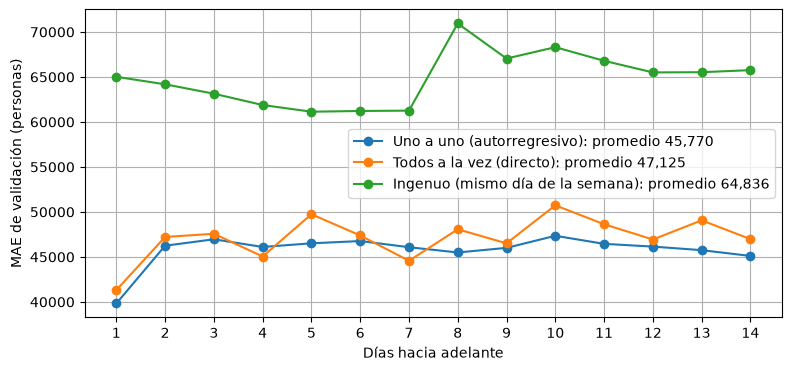

In [12]:
# Ingenuo: el día t+1+h se pronostica con el mismo día de la semana dentro de la última semana de la ventana
Y_naive = torch.stack([X_valid[:, -7 + (h % 7), 0] for h in range(horizon)], dim=1)

def mae_per_day(Y_pred):
    return ((Y_pred - Y_valid).abs().mean(dim=0) * 1e6).numpy()

days = np.arange(1, horizon + 1)
fig, ax = plt.subplots(figsize=(9, 4))
for name, Y_pred in [("Uno a uno (autorregresivo)", Y_auto), ("Todos a la vez (directo)", Y_direct),
                     ("Ingenuo (mismo día de la semana)", Y_naive)]:
    errors = mae_per_day(Y_pred)
    ax.plot(days, errors, marker="o", label=f"{name}: promedio {errors.mean():,.0f}")
ax.set_xlabel("Días hacia adelante"); ax.set_ylabel("MAE de validación (personas)")
ax.set_xticks(days); ax.grid(); ax.legend()
plt.show()

Para leer la gráfica (los números cambian un poco en cada ejecución):

- Las dos redes le ganan con claridad al pronóstico ingenuo en todos los días del horizonte.
- El error más bajo está en el **día 1**: pronosticar mañana es más fácil que pronosticar dentro de dos semanas. Después el error sube y se mantiene más o menos estable.
- En teoría, la estrategia **uno a uno** acumula errores, porque lee sus propios pronósticos; la **directa** no, pero tiene que aprender a mirar más lejos con una sola salida. En esta serie, cuyo patrón semanal es muy regular, las dos quedan muy parecidas. En series más irregulares la diferencia suele ser mayor, y por eso conviene probar ambas.

Por último, veamos un ejemplo concreto: una ventana de validación y los 14 días que pronostica cada estrategia.

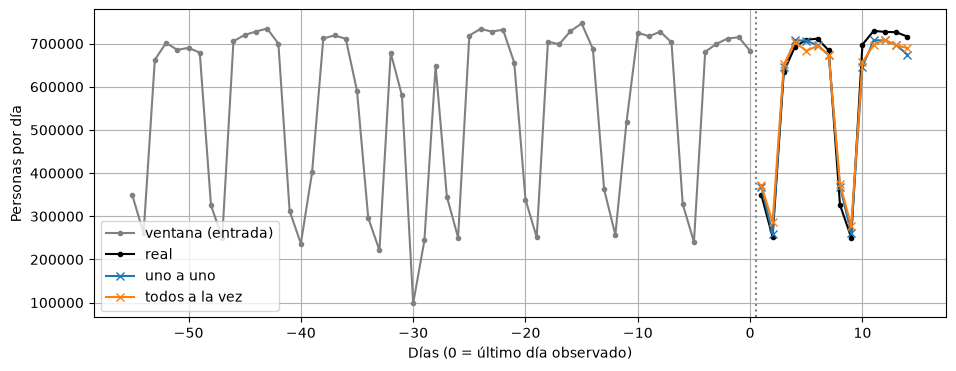

In [13]:
i = 60  # una ventana cualquiera de validación (prueben con otras)
past = np.arange(-window_length + 1, 1)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(past, X_valid[i, :, 0] * 1e6, marker=".", color="gray", label="ventana (entrada)")
ax.plot(days, Y_valid[i] * 1e6, marker=".", color="black", label="real")
ax.plot(days, Y_auto[i] * 1e6, marker="x", label="uno a uno")
ax.plot(days, Y_direct[i] * 1e6, marker="x", label="todos a la vez")
ax.axvline(0.5, color="gray", ls=":")
ax.set_xlabel("Días (0 = último día observado)"); ax.set_ylabel("Personas por día")
ax.grid(); ax.legend()
plt.show()

Las dos estrategias aprenden a repetir el patrón semanal hacia adelante. La diferencia aparece en los detalles: cómo reaccionan a un día atípico dentro de la ventana y qué tanto se alejan de la realidad en los últimos días del horizonte.

En la presentación vimos una tercera opción, el **codificador–decodificador**, que combina las dos ideas: un codificador resume la ventana y un decodificador genera los días futuros uno a uno. Con estas bases ya tenemos lo necesario para la actividad de la unidad: pronosticar la temperatura con datos meteorológicos reales.